In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
if not os.path.exists('/content/pumpkin_data'):
    !unzip -q "/content/drive/MyDrive/Original Dataset.zip" -d /content/pumpkin_data

Mounted at /content/drive


In [3]:
# Settings from Kumar et al. (2026) - ResNet50 Pipeline
# Reference [11]: "ResNet50 pipeline for multi-class pumpkin leaf disease diagnosis in field conditions"
# Transfer learning pipeline reached 91% accuracy
import json, time, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, datasets, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

IMG, BS, LR, EPOCHS = 224, 8, 1e-5, 50      # 224x224, batch 8, lr 1e-5, 50 epochs
STEP, GAMMA = 5, 0.1                         # lr x0.1 every 5 epochs
WD = 1e-4                                    # Adam weight decay
SPLIT_SEED, SEED = 42, 42                    # SEED: change for repeat runs
OUT = '/content/drive/MyDrive/pumpkin_runs'
os.makedirs(OUT, exist_ok=True)
RUN = f'resnet50_kumar_seed{SEED}'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print(device)

cuda


In [4]:
def find_root(base):
    for r, dirs, _ in os.walk(base):
        if len(dirs) == 5 and all(any(f.lower().endswith(('.jpg','.jpeg','.png')) for f in os.listdir(os.path.join(r, d))) for d in dirs):
            return r
ROOT = find_root('/content/pumpkin_data')
full = datasets.ImageFolder(ROOT); classes = full.classes
paths  = [os.path.relpath(p, ROOT) for p, _ in full.samples]
labels = np.array([y for _, y in full.samples])

# 80-10-10 Stratified Split
split_file = f'{OUT}/split_801010_seed{SPLIT_SEED}.json'
if os.path.exists(split_file):
    split = json.load(open(split_file))
else:
    idx = np.arange(len(paths))
    tr, tmp = train_test_split(idx, test_size=0.20, stratify=labels, random_state=SPLIT_SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=SPLIT_SEED)
    split = dict(train=[paths[i] for i in tr], val=[paths[i] for i in va], test=[paths[i] for i in te])
    json.dump(split, open(split_file, 'w'))

tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
ds = datasets.ImageFolder(ROOT, transform=tf)
p2i = {p: i for i, p in enumerate(paths)}
sub = lambda k: Subset(ds, [p2i[p] for p in split[k]])
g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(sub('train'), batch_size=BS, shuffle=True, num_workers=2, generator=g)
val_loader   = DataLoader(sub('val'),   batch_size=BS, num_workers=2)
test_loader  = DataLoader(sub('test'),  batch_size=BS, num_workers=2)
print(classes, {k: len(v) for k, v in split.items()})

['Bacterial Leaf Spot', 'Downy Mildew', 'Healthy Leaf', 'Mosaic Disease', 'Powdery_Mildew'] {'train': 1600, 'val': 200, 'test': 200}


In [5]:
# Model: ResNet-50
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"ResNet-50 initialized with {n_params:.2f}M parameters")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP, gamma=GAMMA)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train: optimizer.zero_grad()
            out = model(x); loss = criterion(out, y)
            if train: loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
    return loss_sum / total, correct / total

ckpt = f'{OUT}/best_{RUN}.pth'
best_val, hist, t0 = 0.0, [], time.time()
for ep in range(EPOCHS):
    s = time.time()
    tl, ta = run_epoch(train_loader, True); vl, va = run_epoch(val_loader, False)
    scheduler.step()
    saved = va > best_val
    if saved: best_val = va; torch.save(model.state_dict(), ckpt)
    hist.append(dict(epoch=ep+1, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va))
    print(f"Epoch {ep+1}/{EPOCHS} | train {tl:.4f}/{ta:.4f} | val {vl:.4f}/{va:.4f} | {time.time()-s:.0f}s{'  <- saved' if saved else ''}")
train_min = (time.time() - t0) / 60
pd.DataFrame(hist).to_csv(f'{OUT}/history_{RUN}.csv', index=False)
print(f'best val acc {best_val:.4f} | {train_min:.1f} min')

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 172MB/s]


ResNet-50 initialized with 23.52M parameters
Epoch 1/50 | train 1.0869/0.6663 | val 0.5713/0.8250 | 24s  <- saved
Epoch 2/50 | train 0.5675/0.8194 | val 0.4373/0.8300 | 22s  <- saved
Epoch 3/50 | train 0.3857/0.8719 | val 0.3915/0.8650 | 22s  <- saved
Epoch 4/50 | train 0.2849/0.9156 | val 0.4007/0.8550 | 22s
Epoch 5/50 | train 0.1824/0.9563 | val 0.3910/0.8600 | 23s
Epoch 6/50 | train 0.1509/0.9669 | val 0.4070/0.8600 | 23s
Epoch 7/50 | train 0.1240/0.9812 | val 0.3965/0.8600 | 23s
Epoch 8/50 | train 0.1232/0.9788 | val 0.3956/0.8700 | 23s  <- saved
Epoch 9/50 | train 0.1155/0.9762 | val 0.3838/0.8600 | 23s
Epoch 10/50 | train 0.1174/0.9762 | val 0.3887/0.8650 | 23s
Epoch 11/50 | train 0.1006/0.9862 | val 0.3963/0.8650 | 23s
Epoch 12/50 | train 0.1070/0.9794 | val 0.3934/0.8700 | 23s
Epoch 13/50 | train 0.1157/0.9800 | val 0.3957/0.8650 | 23s
Epoch 14/50 | train 0.1184/0.9762 | val 0.3856/0.8650 | 23s
Epoch 15/50 | train 0.0955/0.9881 | val 0.3877/0.8600 | 23s
Epoch 16/50 | train 0.10

TEST acc 0.8550 | weighted precision 0.8604 recall 0.8550 | macro F1 0.8513   (paper [11]: 91.0%)
                     precision    recall  f1-score   support

Bacterial Leaf Spot     0.7805    0.8000    0.7901        40
       Downy Mildew     0.8298    0.9750    0.8966        40
       Healthy Leaf     0.8605    0.9250    0.8916        40
     Mosaic Disease     0.9024    0.9250    0.9136        40
     Powdery_Mildew     0.9286    0.6500    0.7647        40

           accuracy                         0.8550       200
          macro avg     0.8604    0.8550    0.8513       200
       weighted avg     0.8604    0.8550    0.8513       200



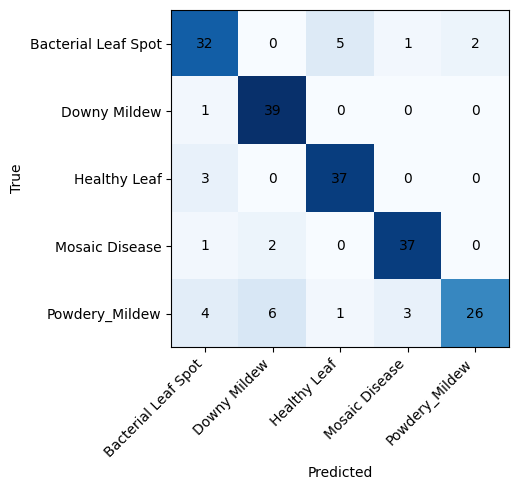

,0
Model,ResNet-50
Reference,[11]
Seed,42
Split,80/10/10
Split file,/content/drive/MyDrive/pumpkin_runs/split_8010...
Input size,224x224
Epochs,50
Batch size,8
Learning rate,0.00001
Optimizer,"Adam wd=0.0001, StepLR 5/0.1"


In [6]:
model.load_state_dict(torch.load(ckpt)); model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        y_pred += model(x.to(device)).argmax(1).cpu().tolist(); y_true += y.tolist()

acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
prec, rec, f1w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
_, _, f1m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
print(f'TEST acc {acc:.4f} | weighted precision {prec:.4f} recall {rec:.4f} | macro F1 {f1m:.4f}   (paper [11]: 91.0%)')
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticklabels(classes, rotation=45, ha='right'); ax.set_yticklabels(classes)
for i in range(5):
    for j in range(5): ax.text(j, i, cm[i, j], ha='center', va='center')
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); plt.tight_layout(); plt.savefig(f'{OUT}/cm_{RUN}.png', dpi=150); plt.show()

row = {'Model': 'ResNet-50', 'Reference': '[11]', 'Seed': SEED, 'Split': '80/10/10', 'Split file': split_file,
       'Input size': '224x224', 'Epochs': EPOCHS, 'Batch size': BS, 'Learning rate': LR,
       'Optimizer': f'Adam wd={WD}, StepLR {STEP}/{GAMMA}', 'Augmentation': 'None',
       'Best val acc': round(best_val, 4), 'Test acc': round(acc, 4), 'Macro F1': round(f1m, 4),
       'Params (M)': round(n_params, 2), 'Train time (min)': round(train_min, 1),
       'Notebook file': 'pumpkin_resnet50.ipynb', 'Checkpoint path': ckpt}
log = f'{OUT}/run_log.csv'
pd.DataFrame([row]).to_csv(log, mode='a', header=not os.path.exists(log), index=False)
pd.DataFrame([row]).T